In [6]:
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    r2_score
)
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import logging

logger = logging.getLogger(__name__)
poly_reg = PolynomialFeatures(degree=2)
lin_reg = LinearRegression()

In [ ]:
def _dataset_set_info(path):
    dataset = pd.read_csv(path)
    logger.info(f'{dataset.info()}\n\n')
    logger.info(f'\n{dataset.head()}\n\n')
    logger.info(f'\n{dataset.isnull().sum()}\n\n')

    return dataset
    



dataset = _dataset_set_info('datasets/fish_market.csv')

<class 'pandas.DataFrame'>
RangeIndex: 159 entries, 0 to 158
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Species  159 non-null    str    
 1   Weight   159 non-null    float64
 2   Length1  159 non-null    float64
 3   Length2  159 non-null    float64
 4   Length3  159 non-null    float64
 5   Height   159 non-null    float64
 6   Width    159 non-null    float64
dtypes: float64(6), str(1)
memory usage: 8.8 KB
[17/Nov/2026 15:11:38] INFO - None


[17/Nov/2026 15:11:38] INFO - 
  Species  Weight  Length1  Length2  Length3   Height   Width
0   Bream   242.0     23.2     25.4     30.0  11.5200  4.0200
1   Bream   290.0     24.0     26.3     31.2  12.4800  4.3056
2   Bream   340.0     23.9     26.5     31.1  12.3778  4.6961
3   Bream   363.0     26.3     29.0     33.5  12.7300  4.4555
4   Bream   430.0     26.5     29.0     34.0  12.4440  5.1340


[17/Nov/2026 15:11:38] INFO - 
Species    0
Weight     0
Length1    0
Lengt

In [19]:
def _preprocessing_dataset(dataset: pd.DataFrame, dependent_feature, categoric_columns, numeric_columns):
    X = dataset.drop(columns=[dependent_feature])
    y = dataset[dependent_feature]

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

    transformer = ColumnTransformer(
        [
            ('num', StandardScaler(), numeric_columns),
            ('cat', OneHotEncoder(), categoric_columns)
        ],
        remainder='passthrough'
    )

    X_train = transformer.fit_transform(X_train)
    X_test = transformer.transform(X_test)

    return X_train, X_test, y_train, y_test

X_train, X_test, y_train, y_test = _preprocessing_dataset(
    dataset=dataset,
    dependent_feature='Weight',
    categoric_columns=['Species'],
    numeric_columns=['Length1','Length2','Length3','Height','Width']
)    

In [24]:
def _set_polynomial_model(X_train, X_test, y_train):

    poly_reg = PolynomialFeatures(degree=2)
    lin_reg = LinearRegression()

    X_train_poly = poly_reg.fit_transform(X_train)
    X_test_poly = poly_reg.transform(X_test)
    lin_reg.fit(X_train_poly, y_train)
    y_pred = lin_reg.predict(X_test_poly)


    return X_train_poly, X_test_poly, y_pred

X_train_poly, X_test_poly, y_pred = _set_polynomial_model(X_train, X_test, y_train)

In [26]:
def show_grafic_metrics(y_test, y_pred):
  # Configurando o estilo dos gráficos
  sns.set_theme(style="whitegrid")
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

  # 1. Gráfico de Dispersão: Valores Reais vs. Preditos
  ax1.scatter(y_test, y_pred, color='blue', alpha=0.7, edgecolors='k', s=80)
  # Linha de referência (Predição Perfeita)
  lims = [min(min(y_test), min(y_pred)), max(max(y_test), max(y_pred))]
  ax1.plot(lims, lims, color='red', linestyle='--', lw=2, label='Predição Perfeita')
  ax1.set_xlabel('Valores Reais', fontsize=12)
  ax1.set_ylabel('Valores Preditos)', fontsize=12)
  ax1.set_title('Valores Reais vs. Valores Preditos', fontsize=14)
  ax1.legend()

  # 2. Gráfico de Resíduos (Erros)
  residuals = y_test - y_pred
  ax2.scatter(y_pred, residuals, color='purple', alpha=0.7, edgecolors='k', s=80)
  ax2.axhline(y=0, color='red', linestyle='--', lw=2)
  ax2.set_xlabel('Valores Preditos', fontsize=12)
  ax2.set_ylabel('Resíduos (Erros)', fontsize=12)
  ax2.set_title('Gráfico de Resíduos (Análise de Erro)', fontsize=14)

  plt.tight_layout()
  plt.show()

  # Calculando as métricas
  mae = mean_absolute_error(y_test, y_pred)
  mse = mean_squared_error(y_test, y_pred)
  rmse = root_mean_squared_error(y_test, y_pred)
  r2 = r2_score(y_test, y_pred)

  # Média dos valores reais para servir de base para os erros (MAE/RMSE)
  media_y = np.mean(y_test)
  
  print('\n RESULTADOS TREINAMENTO')
  print(f'MAE (Erro Médio Absoluto): {mae:.4f} | (Ideal: perto de 0 | Média real: {media_y:.2f})')
  print(f'MSE (Erro Quadrático Médio): {mse:.4f} | (Ideal: perto de 0 | Penaliza erros grandes)')
  print(f'RMSE (Raiz do Erro Quadrático): {rmse:.4f} | (Ideal: perto de 0 | Mesma unidade do alvo)')
  print(f'R2_SCORE (Coeficiente R²): {r2:.4f} | (Ref: <0.70 Ruim | 0.70-0.89 Bom | >=0.90 Excelente)')

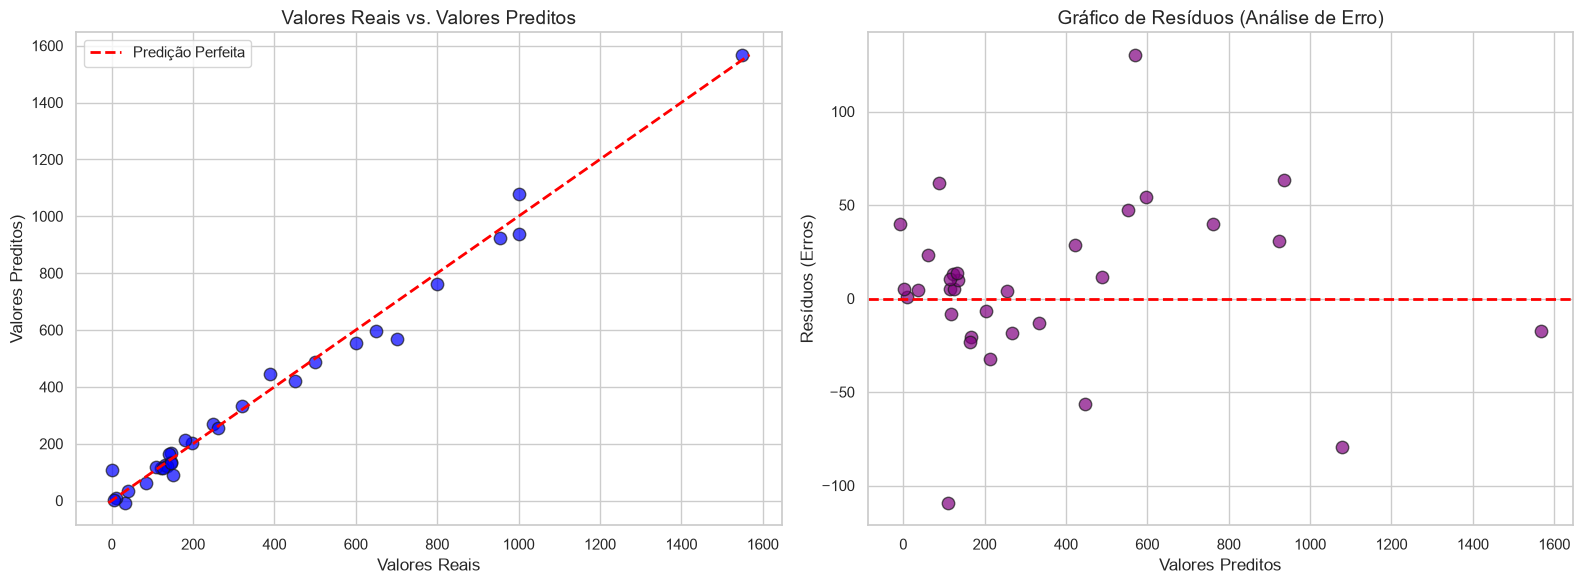


 RESULTADOS TREINAMENTO
MAE (Erro Médio Absoluto): 30.8627 | (Ideal: perto de 0 | Média real: 353.77)
MSE (Erro Quadrático Médio): 1893.8321 | (Ideal: perto de 0 | Penaliza erros grandes)
RMSE (Raiz do Erro Quadrático): 43.5182 | (Ideal: perto de 0 | Mesma unidade do alvo)
R2_SCORE (Coeficiente R²): 0.9860 | (Ref: <0.70 Ruim | 0.70-0.89 Bom | >=0.90 Excelente)


In [27]:
show_grafic_metrics(y_test, y_pred)